In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 한글 폰트 설정
plt.rc('font', family='Malgun Gothic')
plt.rc('axes', unicode_minus=False)


In [2]:

# 1. 데이터 로드
# 현재 폴더부터 상위로 올라가며 data 폴더 탐색
data_dir = next(p / 'data' for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'secom.data').exists())

df_features = pd.read_csv(data_dir / 'secom.data', sep=r'\s+', header=None)
df_labels = pd.read_csv(
    data_dir / 'secom_labels.data',
    sep=r'\s+',
    header=None,
    usecols=[0],
    names=['Target'],
)

# 타깃 정의: 0 (PASS), 1 (FAIL)
target = (df_labels['Target'] == 1).astype(int)


In [3]:

# 2. Sensor_59, Sensor_103 추출 및 결합
target_sensors = [59, 103]
sensor_cols = [f'Sensor_{i}' for i in target_sensors]

df_target = df_features[target_sensors].copy()
df_target.columns = sensor_cols
df_target['Result'] = target.map({0: 'PASS', 1: 'FAIL'})

# 3. 정상 vs 불량 통계적 특성 비교표
stats_list = []
for col in sensor_cols:
  pass_data = df_target[df_target['Result'] == 'PASS'][col].dropna()
  fail_data = df_target[df_target['Result'] == 'FAIL'][col].dropna()

  stats_list.append({
      '센서': col,
      'PASS 평균': pass_data.mean(),
      'FAIL 평균': fail_data.mean(),
      '평균 차이(FAIL - PASS)': fail_data.mean() - pass_data.mean(),
      'PASS 중앙값': pass_data.median(),
      'FAIL 중앙값': fail_data.median(),
      'PASS 표준편차': pass_data.std(),
      'FAIL 표준편차': fail_data.std(),
  })

stats_df = pd.DataFrame(stats_list)
print('=== 핵심 센서(59, 103) 정상 vs 불량 통계 비교 ===')
display(
    stats_df.style.format({
        'PASS 평균': '{:.4f}',
        'FAIL 평균': '{:.4f}',
        '평균 차이(FAIL - PASS)': '{:.4f}',
        'PASS 중앙값': '{:.4f}',
        'FAIL 중앙값': '{:.4f}',
        'PASS 표준편차': '{:.4f}',
        'FAIL 표준편차': '{:.4f}',
    })
)


=== 핵심 센서(59, 103) 정상 vs 불량 통계 비교 ===


,센서,PASS 평균,FAIL 평균,평균 차이(FAIL - PASS),PASS 중앙값,FAIL 중앙값,PASS 표준편차,FAIL 표준편차
0,Sensor_59,2.5635,8.5151,5.9517,0.7223,5.5223,9.3131,10.8023
1,Sensor_103,-0.0099,-0.0081,0.0019,-0.0102,-0.0082,0.0030,0.0035


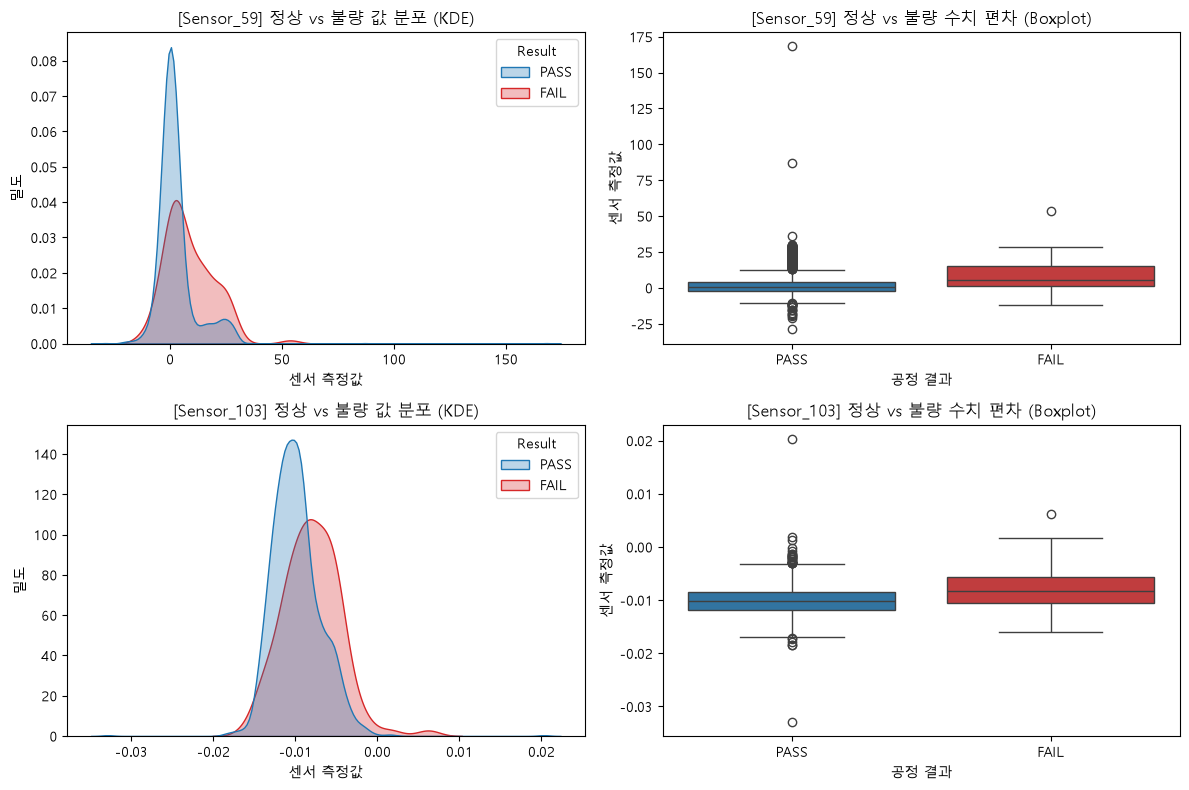

In [4]:

# 4. 시각화 (KDE 밀도 곡선 & 박스플롯)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for idx, col in enumerate(sensor_cols):
  # 좌측: KDE 밀도 분포
  sns.kdeplot(
      data=df_target,
      x=col,
      hue='Result',
      common_norm=False,
      ax=axes[idx, 0],
      palette={'PASS': '#1f77b4', 'FAIL': '#d62728'},
      fill=True,
      alpha=0.3,
  )
  axes[idx, 0].set_title(f'[{col}] 정상 vs 불량 값 분포 (KDE)')
  axes[idx, 0].set_xlabel('센서 측정값')
  axes[idx, 0].set_ylabel('밀도')

  # 우측: 박스플롯
  sns.boxplot(
      data=df_target,
      x='Result',
      y=col,
      hue='Result',
      legend=False,
      ax=axes[idx, 1],
      palette={'PASS': '#1f77b4', 'FAIL': '#d62728'},
  )
  axes[idx, 1].set_title(f'[{col}] 정상 vs 불량 수치 편차 (Boxplot)')
  axes[idx, 1].set_xlabel('공정 결과')
  axes[idx, 1].set_ylabel('센서 측정값')

plt.tight_layout()
plt.show()